In [1]:
import os

for root, dirs, files in os.walk('/kaggle/input'):
    print(root)

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/jshanky
/kaggle/input/datasets/jshanky/zenodo
/kaggle/input/datasets/jshanky/zenodo/Zenodo
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset/images
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset/images


In [2]:
import os
import shutil
import pandas as pd

# Original dataset paths
train_source = '/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset'
test_source = '/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset'

# Label files
train_excel = os.path.join(train_source, 'class_label.xlsx')
test_csv = os.path.join(test_source, 'class label.csv')

# Image folders
train_images = os.path.join(train_source, 'images')
test_images = os.path.join(test_source, 'images')

# New folders for ImageFolder
output_root = '/kaggle/working/PCOSGen-train'

train_dir = os.path.join(output_root, 'train')
test_dir = os.path.join(output_root, 'test')

# Create class folders
for directory in [
    os.path.join(train_dir, 'Appears normal'),
    os.path.join(train_dir, 'Appears abnormal'),
    os.path.join(test_dir, 'Appears normal'),
    os.path.join(test_dir, 'Appears abnormal')
]:
    os.makedirs(directory, exist_ok=True)

# Read labels
train_df = pd.read_excel(train_excel)
test_df = pd.read_csv(test_csv)

# Column we actually want
label_column = 'Class label (whether the ultrasound images appears normal or has some abnormality)'

# Function to copy images according to labels
def prepare_dataset(df, image_source, output_dir):
    copied = 0
    skipped = 0

    for _, row in df.iterrows():

        image_path = str(row['imagePath']).strip()
        label = str(row[label_column]).strip().lower()

        # Ignore Unknown / missing labels
        if label == 'unknown' or label == 'nan':
            skipped += 1
            continue

        # Determine target class
        if 'normal' in label and 'abnormal' not in label:
            class_name = 'Appears normal'
        elif 'abnormal' in label:
            class_name = 'Appears abnormal'
        else:
            skipped += 1
            continue

        # ImagePath may contain directories, so use only the filename
        image_name = os.path.basename(image_path)
        source_file = os.path.join(image_source, image_name)

        if not os.path.exists(source_file):
            skipped += 1
            continue

        destination = os.path.join(output_dir, class_name, image_name)

        shutil.copy2(source_file, destination)
        copied += 1

    return copied, skipped


# Prepare train and test
train_copied, train_skipped = prepare_dataset(
    train_df,
    train_images,
    train_dir
)

test_copied, test_skipped = prepare_dataset(
    test_df,
    test_images,
    test_dir
)

print("Dataset preparation complete!")
print(f"Train images copied : {train_copied}")
print(f"Train images skipped: {train_skipped}")
print(f"Test images copied  : {test_copied}")
print(f"Test images skipped : {test_skipped}")

Dataset preparation complete!
Train images copied : 3200
Train images skipped: 1
Test images copied  : 1468
Test images skipped : 0


In [3]:
from collections import Counter
import os

for split in ['train', 'test']:
    print(f"\n{split.upper()}")

    for class_name in ['Appears normal', 'Appears abnormal']:
        path = os.path.join(output_root, split, class_name)
        count = len(os.listdir(path))
        print(f"{class_name}: {count}")


TRAIN
Appears normal: 903
Appears abnormal: 2297

TEST
Appears normal: 416
Appears abnormal: 1052


In [9]:
# ============================================================
# CELL 1 — IMPORTS
# ============================================================

import os
import copy
import random
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import (
    Dataset,
    DataLoader
)

from torchvision import datasets
from torchvision import transforms
from torchvision import models

from PIL import Image

import matplotlib.pyplot as plt

from tqdm.auto import tqdm

# HuggingFace Transformer
from transformers import SegformerModel

# Traditional ML
from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier
)

from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

print("All libraries imported successfully.")

All libraries imported successfully.


In [10]:
# ============================================================
# CELL 2 — DEVICE, PATHS & REPRODUCIBILITY
# ============================================================

# -----------------------------
# Reproducibility
# -----------------------------
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

# Make CUDA operations as reproducible as practical
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


# -----------------------------
# Device
# -----------------------------
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# -----------------------------
# Dataset paths
# -----------------------------
TRAIN_DIR = "/kaggle/working/PCOSGen-train/train"
TEST_DIR  = "/kaggle/working/PCOSGen-train/test"


# -----------------------------
# Check paths
# -----------------------------
print("\nDataset paths:")
print("Train:", TRAIN_DIR)
print("Test :", TEST_DIR)

print("\nTrain path exists:", os.path.exists(TRAIN_DIR))
print("Test path exists :", os.path.exists(TEST_DIR))


# -----------------------------
# Basic folder check
# -----------------------------
if os.path.exists(TRAIN_DIR):
    print("\nTrain classes:")
    print(sorted(os.listdir(TRAIN_DIR)))

if os.path.exists(TEST_DIR):
    print("\nTest classes:")
    print(sorted(os.listdir(TEST_DIR)))

Device: cuda
GPU: Tesla T4

Dataset paths:
Train: /kaggle/working/PCOSGen-train/train
Test : /kaggle/working/PCOSGen-train/test

Train path exists: True
Test path exists : True

Train classes:
['Appears abnormal', 'Appears normal']

Test classes:
['Appears abnormal', 'Appears normal']


In [11]:
# ============================================================
# CELL 3 — DATASET + 85/15 TRAIN-VALIDATION SPLIT
# ============================================================

from torch.utils.data import Subset

# ------------------------------------------------------------
# Image settings
# ------------------------------------------------------------
IMG_SIZE = 224

# ------------------------------------------------------------
# Training transforms
# Augmentation is applied ONLY to training samples
# ------------------------------------------------------------
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=20),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ------------------------------------------------------------
# Validation / Test transforms
# No random augmentation
# ------------------------------------------------------------
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ------------------------------------------------------------
# Load training folder WITHOUT transform
# We need the same indices for train and validation
# ------------------------------------------------------------
full_train_dataset = datasets.ImageFolder(
    root=TRAIN_DIR,
    transform=None
)

# ------------------------------------------------------------
# Load test folder separately
# IMPORTANT: This remains completely untouched until
# final evaluation.
# ------------------------------------------------------------
test_dataset = datasets.ImageFolder(
    root=TEST_DIR,
    transform=eval_transform
)


# ------------------------------------------------------------
# Class information
# ------------------------------------------------------------
class_names = full_train_dataset.classes
num_classes = len(class_names)

print("Classes:", class_names)
print("Number of classes:", num_classes)


# ------------------------------------------------------------
# 85 / 15 split
# Stratified split so class proportions are preserved
# ------------------------------------------------------------
from sklearn.model_selection import train_test_split

all_indices = np.arange(len(full_train_dataset))
all_labels = np.array(full_train_dataset.targets)

train_indices, val_indices = train_test_split(
    all_indices,
    test_size=0.15,
    random_state=SEED,
    stratify=all_labels
)


# ------------------------------------------------------------
# Custom dataset wrapper
# Allows different transforms for train and validation
# ------------------------------------------------------------
class TransformSubset(Dataset):

    def __init__(self, dataset, indices, transform=None):
        self.dataset = dataset
        self.indices = list(indices)
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):

        original_idx = self.indices[idx]

        image, label = self.dataset[original_idx]

        if self.transform is not None:
            image = self.transform(image)

        return image, label


# ------------------------------------------------------------
# Create train / validation datasets
# ------------------------------------------------------------
train_dataset = TransformSubset(
    full_train_dataset,
    train_indices,
    transform=train_transform
)

val_dataset = TransformSubset(
    full_train_dataset,
    val_indices,
    transform=eval_transform
)


# ------------------------------------------------------------
# Dataset sizes
# ------------------------------------------------------------
print("\nDataset sizes:")
print("-----------------------------")
print("Total training-folder images :", len(full_train_dataset))
print("Training images              :", len(train_dataset))
print("Validation images            :", len(val_dataset))
print("Test images                  :", len(test_dataset))
print("-----------------------------")


# ------------------------------------------------------------
# Verify no overlap
# ------------------------------------------------------------
train_set = set(train_indices)
val_set = set(val_indices)

overlap = train_set.intersection(val_set)

print("\nTrain/Validation overlap:", len(overlap))

assert len(overlap) == 0, "ERROR: Train and validation overlap detected!"

print("✓ Train/validation split is clean.")
print("✓ Test set is kept separate.")

Classes: ['Appears abnormal', 'Appears normal']
Number of classes: 2

Dataset sizes:
-----------------------------
Total training-folder images : 3200
Training images              : 2720
Validation images            : 480
Test images                  : 1468
-----------------------------

Train/Validation overlap: 0
✓ Train/validation split is clean.
✓ Test set is kept separate.


In [12]:
# ============================================================
# CELL 4 — DATALOADERS + CLASS DISTRIBUTION
# ============================================================

BATCH_SIZE = 32

# ------------------------------------------------------------
# DataLoaders
# ------------------------------------------------------------

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


# ------------------------------------------------------------
# Class distribution
# ------------------------------------------------------------

train_labels = all_labels[train_indices]
val_labels = all_labels[val_indices]
test_labels = np.array(test_dataset.targets)

print("Class distribution")
print("=" * 50)

for idx, class_name in enumerate(class_names):

    train_count = np.sum(train_labels == idx)
    val_count = np.sum(val_labels == idx)
    test_count = np.sum(test_labels == idx)

    print(f"\nClass: {class_name}")
    print(f"  Train      : {train_count}")
    print(f"  Validation : {val_count}")
    print(f"  Test       : {test_count}")


# ------------------------------------------------------------
# Check one batch
# ------------------------------------------------------------

images, labels = next(iter(train_loader))

print("\n" + "=" * 50)
print("Batch verification")
print("=" * 50)

print("Image batch shape :", images.shape)
print("Label batch shape :", labels.shape)
print("Image dtype       :", images.dtype)
print("Label dtype       :", labels.dtype)

print("\nExpected image shape:")
print("(batch_size, 3, 224, 224)")

Class distribution

Class: Appears abnormal
  Train      : 1952
  Validation : 345
  Test       : 1052

Class: Appears normal
  Train      : 768
  Validation : 135
  Test       : 416

Batch verification
Image batch shape : torch.Size([32, 3, 224, 224])
Label batch shape : torch.Size([32])
Image dtype       : torch.float32
Label dtype       : torch.int64

Expected image shape:
(batch_size, 3, 224, 224)


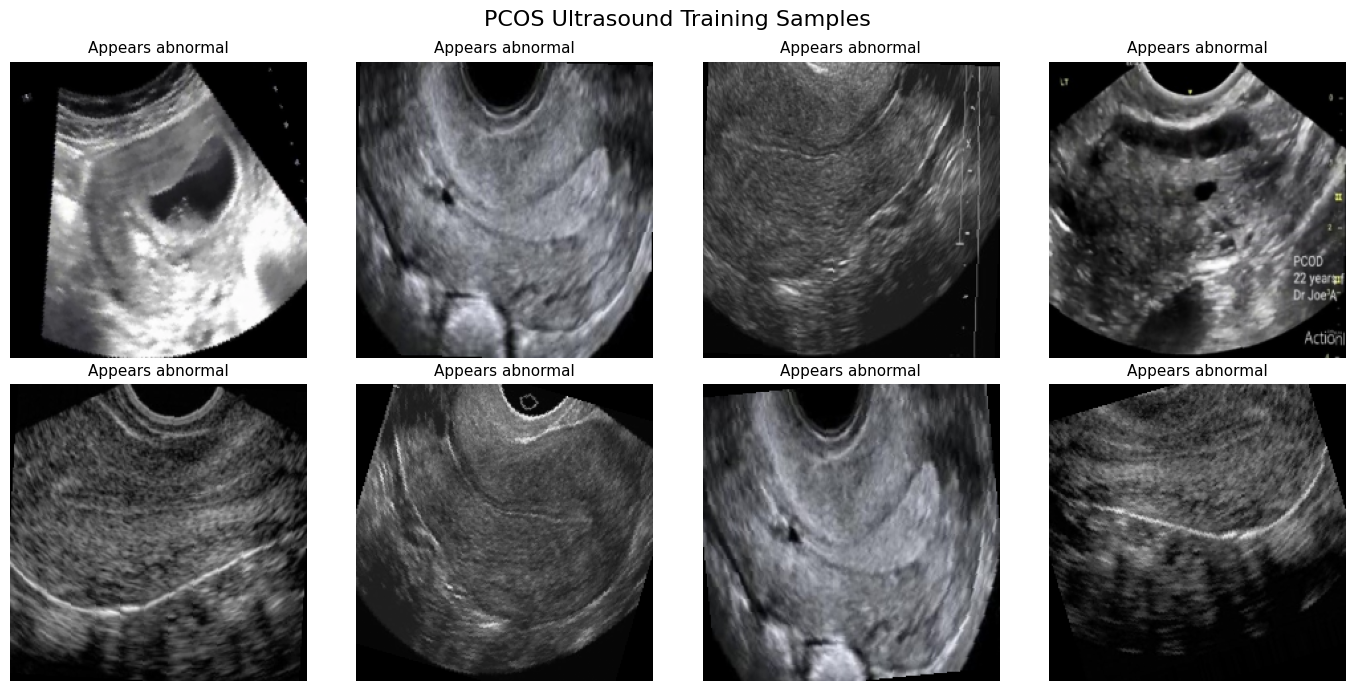

In [13]:
# ============================================================
# CELL 5 — VISUALIZE TRAINING SAMPLES
# ============================================================

# ------------------------------------------------------------
# Get one batch
# ------------------------------------------------------------

images, labels = next(iter(train_loader))


# ------------------------------------------------------------
# ImageNet normalization values
# Used to convert images back for visualization
# ------------------------------------------------------------

mean = torch.tensor(
    [0.485, 0.456, 0.406]
).view(3, 1, 1)

std = torch.tensor(
    [0.229, 0.224, 0.225]
).view(3, 1, 1)


# ------------------------------------------------------------
# Plot samples
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for i, ax in enumerate(axes.flat):

    # Convert CHW -> HWC
    image = images[i].cpu() * std + mean
    image = torch.clamp(image, 0, 1)

    image = image.permute(1, 2, 0).numpy()

    ax.imshow(image)

    ax.set_title(
        class_names[labels[i].item()],
        fontsize=11
    )

    ax.axis("off")


plt.suptitle(
    "PCOS Ultrasound Training Samples",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [14]:
# ============================================================
# CELL 6 — MiT-B2 + FPN CLASSIFICATION MODEL
# ============================================================

# ------------------------------------------------------------
# MiT-B2 Feature + FPN Model
# ------------------------------------------------------------

class MiTB2_FPN_Classifier(nn.Module):

    def __init__(self, num_classes=2, fpn_channels=256):

        super().__init__()

        # ----------------------------------------------------
        # MiT-B2 Transformer backbone
        # ----------------------------------------------------
        self.mit = SegformerModel.from_pretrained(
            "nvidia/mit-b2"
        )

        # MiT-B2 encoder output channels
        # Stage 1 = 64
        # Stage 2 = 128
        # Stage 3 = 320
        # Stage 4 = 512
        self.stage_channels = [64, 128, 320, 512]

        # ----------------------------------------------------
        # FPN lateral projections
        # ----------------------------------------------------
        self.lateral_convs = nn.ModuleList([
            nn.Conv2d(
                in_channels=c,
                out_channels=fpn_channels,
                kernel_size=1
            )
            for c in self.stage_channels
        ])

        # ----------------------------------------------------
        # FPN refinement
        # ----------------------------------------------------
        self.fpn_refine = nn.Sequential(
            nn.Conv2d(
                fpn_channels,
                fpn_channels,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(fpn_channels),
            nn.ReLU(inplace=True)
        )

        # ----------------------------------------------------
        # Global feature extraction
        # ----------------------------------------------------
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))

        # ----------------------------------------------------
        # Classification head
        # ----------------------------------------------------
        self.dropout = nn.Dropout(p=0.3)

        self.classifier = nn.Linear(
            fpn_channels,
            num_classes
        )

    # --------------------------------------------------------
    # Convert HuggingFace hidden state to BCHW
    # --------------------------------------------------------
    def _to_bchw(self, x, expected_channels, height, width):

        # Case 1:
        # Already [B, C, H, W]
        if x.dim() == 4:
            return x

        # Case 2:
        # [B, N, C]
        elif x.dim() == 3:

            B, N, C = x.shape

            if C != expected_channels:
                raise RuntimeError(
                    f"Expected {expected_channels} channels, "
                    f"but received {C}."
                )

            if N != height * width:
                raise RuntimeError(
                    f"Cannot reshape {N} tokens into "
                    f"{height} x {width}."
                )

            x = x.transpose(1, 2)

            x = x.reshape(
                B,
                C,
                height,
                width
            )

            return x

        else:

            raise RuntimeError(
                f"Unexpected tensor dimension: {x.dim()}"
            )

    # --------------------------------------------------------
    # Forward
    # --------------------------------------------------------
    def forward(self, x, return_features=False):

        # ----------------------------------------------------
        # MiT-B2 encoder
        # ----------------------------------------------------
        outputs = self.mit(
            pixel_values=x,
            output_hidden_states=True
        )

        hidden_states = outputs.hidden_states

        # Last 4 encoder stages
        stage_features = hidden_states[-4:]

        # ----------------------------------------------------
        # Expected spatial resolutions for 224x224 input
        # ----------------------------------------------------
        resolutions = [
            (56, 56),
            (28, 28),
            (14, 14),
            (7, 7)
        ]

        processed_features = []

        # ----------------------------------------------------
        # Convert every stage to BCHW
        # ----------------------------------------------------
        for feature, channels, (h, w) in zip(
            stage_features,
            self.stage_channels,
            resolutions
        ):

            feature = self._to_bchw(
                feature,
                channels,
                h,
                w
            )

            processed_features.append(feature)

        # ----------------------------------------------------
        # FPN
        #
        # Start from the highest-resolution feature.
        # Upsample all deeper stages to 56x56.
        # ----------------------------------------------------

        target_size = processed_features[0].shape[-2:]

        fpn_output = 0

        for feature, lateral in zip(
            processed_features,
            self.lateral_convs
        ):

            feature = lateral(feature)

            if feature.shape[-2:] != target_size:

                feature = F.interpolate(
                    feature,
                    size=target_size,
                    mode="bilinear",
                    align_corners=False
                )

            fpn_output = fpn_output + feature

        # ----------------------------------------------------
        # FPN refinement
        # ----------------------------------------------------
        fpn_output = self.fpn_refine(fpn_output)

        # ----------------------------------------------------
        # Global feature vector
        # ----------------------------------------------------
        features = self.global_pool(
            fpn_output
        )

        features = torch.flatten(
            features,
            start_dim=1
        )

        # ----------------------------------------------------
        # Classification
        # ----------------------------------------------------
        logits = self.classifier(
            self.dropout(features)
        )

        # ----------------------------------------------------
        # Return feature vector when requested
        # ----------------------------------------------------
        if return_features:

            return logits, features

        return logits


# ============================================================
# Create model
# ============================================================

mit_fpn_model = MiTB2_FPN_Classifier(
    num_classes=num_classes,
    fpn_channels=256
)

mit_fpn_model = mit_fpn_model.to(device)


# ============================================================
# Verify model
# ============================================================

print("MiT-B2 + FPN model created successfully.")

print("\nTrainable parameters:")
trainable_params = sum(
    p.numel()
    for p in mit_fpn_model.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel()
    for p in mit_fpn_model.parameters()
)

print(f"Trainable parameters : {trainable_params:,}")
print(f"Total parameters     : {total_params:,}")


# ============================================================
# Test forward pass
# ============================================================

with torch.no_grad():

    sample_images, sample_labels = next(
        iter(train_loader)
    )

    sample_images = sample_images.to(device)

    sample_logits, sample_features = mit_fpn_model(
        sample_images,
        return_features=True
    )

print("\nForward-pass verification:")
print("Input shape     :", sample_images.shape)
print("Feature shape   :", sample_features.shape)
print("Logit shape     :", sample_logits.shape)

print("\nExpected:")
print("Feature shape   : [batch_size, 256]")
print("Logit shape     : [batch_size, 2]")

Loading weights:   0%|          | 0/364 [00:00<?, ?it/s]

SegformerModel LOAD REPORT from: nvidia/mit-b2
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


MiT-B2 + FPN model created successfully.

Trainable parameters:
Trainable parameters : 25,050,562
Total parameters     : 25,050,562

Forward-pass verification:
Input shape     : torch.Size([32, 3, 224, 224])
Feature shape   : torch.Size([32, 256])
Logit shape     : torch.Size([32, 2])

Expected:
Feature shape   : [batch_size, 256]
Logit shape     : [batch_size, 2]


In [15]:
# ============================================================
# CELL 7 — MiT-B2 + FPN TRAINING SETUP
# ============================================================

# ------------------------------------------------------------
# Loss function
# ------------------------------------------------------------
criterion_mit = nn.CrossEntropyLoss()


# ------------------------------------------------------------
# Optimizer
#
# Smaller LR for pretrained MiT-B2
# Larger LR for newly initialized FPN + classifier
# ------------------------------------------------------------

mit_backbone_params = []
new_params = []

for name, param in mit_fpn_model.named_parameters():

    if not param.requires_grad:
        continue

    if name.startswith("mit."):
        mit_backbone_params.append(param)
    else:
        new_params.append(param)


optimizer_mit = torch.optim.AdamW(
    [
        {
            "params": mit_backbone_params,
            "lr": 1e-5
        },
        {
            "params": new_params,
            "lr": 1e-4
        }
    ],
    weight_decay=1e-4
)


# ------------------------------------------------------------
# Learning-rate scheduler
# ------------------------------------------------------------

scheduler_mit = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_mit,
    mode="min",
    factor=0.5,
    patience=2
)


# ------------------------------------------------------------
# Training configuration
# ------------------------------------------------------------

NUM_EPOCHS_MIT = 15

best_val_loss_mit = float("inf")
best_val_acc_mit = 0.0

best_mit_state = None

patience_mit = 4
epochs_without_improvement = 0


# ------------------------------------------------------------
# History
# ------------------------------------------------------------

mit_train_losses = []
mit_val_losses = []

mit_train_accs = []
mit_val_accs = []


# ------------------------------------------------------------
# Print setup
# ------------------------------------------------------------

print("MiT-B2 + FPN training setup complete.")
print()
print("Loss function       : CrossEntropyLoss")
print("Optimizer           : AdamW")
print("MiT-B2 learning rate: 1e-5")
print("FPN/head LR         : 1e-4")
print("Weight decay        : 1e-4")
print("Max epochs          :", NUM_EPOCHS_MIT)
print("Early stopping      : patience =", patience_mit)

print("\nTrainable parameter groups:")
print("MiT-B2 parameters   :", sum(p.numel() for p in mit_backbone_params))
print("FPN + classifier    :", sum(p.numel() for p in new_params))

MiT-B2 + FPN training setup complete.

Loss function       : CrossEntropyLoss
Optimizer           : AdamW
MiT-B2 learning rate: 1e-5
FPN/head LR         : 1e-4
Weight decay        : 1e-4
Max epochs          : 15
Early stopping      : patience = 4

Trainable parameter groups:
MiT-B2 parameters   : 24196288
FPN + classifier    : 854274


In [16]:
# ============================================================
# CELL 8 — TRAIN MiT-B2 + FPN
# ============================================================

for epoch in range(NUM_EPOCHS_MIT):

    # ========================================================
    # TRAINING
    # ========================================================

    mit_fpn_model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    train_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{NUM_EPOCHS_MIT} [Train]"
    )

    for images, labels in train_bar:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # Clear gradients
        optimizer_mit.zero_grad(set_to_none=True)

        # Forward pass
        logits = mit_fpn_model(images)

        # Classification loss
        loss = criterion_mit(logits, labels)

        # Backpropagation
        loss.backward()

        # Gradient clipping for stable fine-tuning
        torch.nn.utils.clip_grad_norm_(
            mit_fpn_model.parameters(),
            max_norm=1.0
        )

        # Update weights
        optimizer_mit.step()

        # Statistics
        running_loss += loss.item() * images.size(0)

        predictions = torch.argmax(
            logits,
            dim=1
        )

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

        train_bar.set_postfix(
            loss=f"{loss.item():.4f}",
            acc=f"{correct / total:.4f}"
        )

    epoch_train_loss = running_loss / total
    epoch_train_acc = correct / total


    # ========================================================
    # VALIDATION
    # ========================================================

    mit_fpn_model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        val_bar = tqdm(
            val_loader,
            desc=f"Epoch {epoch + 1}/{NUM_EPOCHS_MIT} [Val]"
        )

        for images, labels in val_bar:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            # Forward pass
            logits = mit_fpn_model(images)

            # Validation loss
            loss = criterion_mit(
                logits,
                labels
            )

            val_running_loss += (
                loss.item() * images.size(0)
            )

            predictions = torch.argmax(
                logits,
                dim=1
            )

            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += labels.size(0)

            val_bar.set_postfix(
                loss=f"{loss.item():.4f}",
                acc=f"{val_correct / val_total:.4f}"
            )

    epoch_val_loss = val_running_loss / val_total
    epoch_val_acc = val_correct / val_total


    # ========================================================
    # SAVE HISTORY
    # ========================================================

    mit_train_losses.append(epoch_train_loss)
    mit_val_losses.append(epoch_val_loss)

    mit_train_accs.append(epoch_train_acc)
    mit_val_accs.append(epoch_val_acc)


    # ========================================================
    # LR SCHEDULER
    # ========================================================

    scheduler_mit.step(epoch_val_loss)


    # ========================================================
    # PRINT RESULTS
    # ========================================================

    current_lr_backbone = optimizer_mit.param_groups[0]["lr"]
    current_lr_head = optimizer_mit.param_groups[1]["lr"]

    print("\n" + "=" * 70)

    print(
        f"Epoch [{epoch + 1}/{NUM_EPOCHS_MIT}]"
    )

    print(
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Train Acc: {epoch_train_acc:.4f}"
    )

    print(
        f"Val Loss:   {epoch_val_loss:.4f} | "
        f"Val Acc:   {epoch_val_acc:.4f}"
    )

    print(
        f"MiT LR: {current_lr_backbone:.2e} | "
        f"FPN/Head LR: {current_lr_head:.2e}"
    )


    # ========================================================
    # BEST MODEL
    # We select using VALIDATION LOSS only.
    # ========================================================

    if epoch_val_loss < best_val_loss_mit:

        best_val_loss_mit = epoch_val_loss
        best_val_acc_mit = epoch_val_acc

        best_mit_state = copy.deepcopy(
            mit_fpn_model.state_dict()
        )

        epochs_without_improvement = 0

        print("✓ Best MiT-B2 + FPN model saved.")

    else:

        epochs_without_improvement += 1

        print(
            f"No validation-loss improvement "
            f"({epochs_without_improvement}/{patience_mit})"
        )


    # ========================================================
    # EARLY STOPPING
    # ========================================================

    if epochs_without_improvement >= patience_mit:

        print("\nEarly stopping triggered.")

        break


# ============================================================
# RESTORE BEST MODEL
# ============================================================

if best_mit_state is not None:

    mit_fpn_model.load_state_dict(
        best_mit_state
    )

print("\n" + "=" * 70)
print("MiT-B2 + FPN training complete.")
print(f"Best validation loss: {best_val_loss_mit:.4f}")
print(f"Best validation accuracy: {best_val_acc_mit:.4f}")
print("=" * 70)

Epoch 1/15 [Train]:   0%|          | 0/85 [00:00<?, ?it/s]

Epoch 1/15 [Val]:   0%|          | 0/15 [00:00<?, ?it/s]


Epoch [1/15]
Train Loss: 0.5114 | Train Acc: 0.7434
Val Loss:   0.4965 | Val Acc:   0.7417
MiT LR: 1.00e-05 | FPN/Head LR: 1.00e-04
✓ Best MiT-B2 + FPN model saved.


Epoch 2/15 [Train]:   0%|          | 0/85 [00:00<?, ?it/s]

Epoch 2/15 [Val]:   0%|          | 0/15 [00:00<?, ?it/s]

...

Epoch 8/15 [Val]:   0%|          | 0/15 [00:00<?, ?it/s]


Epoch [8/15]
Train Loss: 0.3998 | Train Acc: 0.7960
Val Loss:   0.4912 | Val Acc:   0.7688
MiT LR: 5.00e-06 | FPN/Head LR: 5.00e-05
No validation-loss improvement (3/4)


Epoch 9/15 [Train]:   0%|          | 0/85 [00:00<?, ?it/s]

Epoch 9/15 [Val]:   0%|          | 0/15 [00:00<?, ?it/s]


Epoch [9/15]
Train Loss: 0.4002 | Train Acc: 0.7868
Val Loss:   0.4855 | Val Acc:   0.7750
MiT LR: 5.00e-06 | FPN/Head LR: 5.00e-05
No validation-loss improvement (4/4)

Early stopping triggered.

MiT-B2 + FPN training complete.
Best validation loss: 0.4708
Best validation accuracy: 0.7750


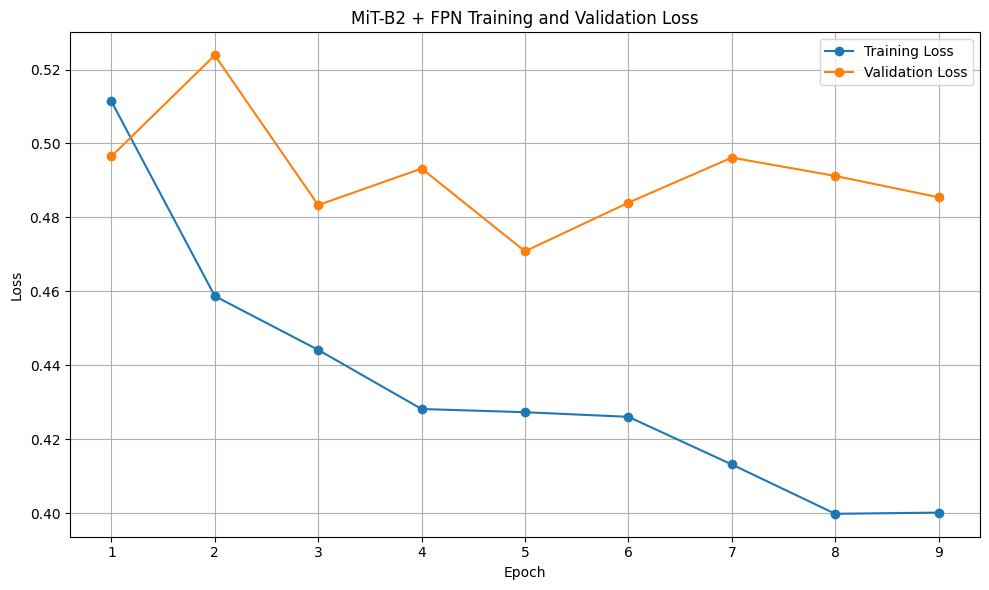

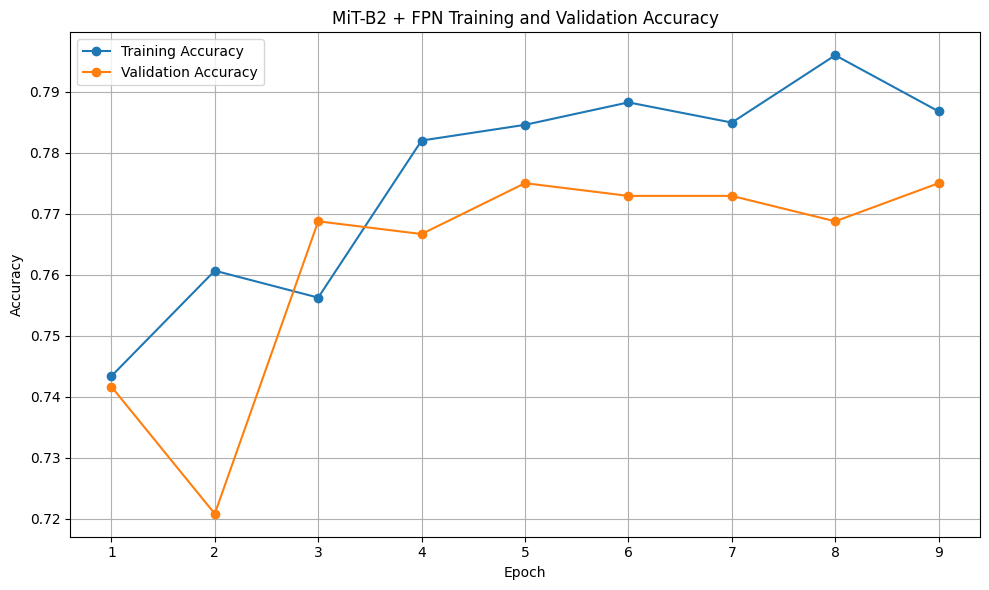

MiT-B2 + FPN TRAINING SUMMARY
Best Epoch          : 5
Best Validation Loss: 0.4708
Validation Accuracy : 0.7750


In [17]:
# ============================================================
# CELL 9 — MiT-B2 + FPN TRAINING GRAPHS
# ============================================================

epochs_completed = range(
    1,
    len(mit_train_losses) + 1
)

# ------------------------------------------------------------
# 1. Loss Curve
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    epochs_completed,
    mit_train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs_completed,
    mit_val_losses,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MiT-B2 + FPN Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. Accuracy Curve
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    epochs_completed,
    mit_train_accs,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs_completed,
    mit_val_accs,
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MiT-B2 + FPN Training and Validation Accuracy")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. Print best validation results
# ------------------------------------------------------------

best_epoch = np.argmin(mit_val_losses) + 1

print("=" * 60)
print("MiT-B2 + FPN TRAINING SUMMARY")
print("=" * 60)

print(f"Best Epoch          : {best_epoch}")
print(f"Best Validation Loss: {min(mit_val_losses):.4f}")
print(
    f"Validation Accuracy : "
    f"{mit_val_accs[best_epoch - 1]:.4f}"
)

print("=" * 60)

In [20]:
# ============================================================
# CELL 10 — MobileNetV2 CLASSIFICATION MODEL
# ============================================================

# ------------------------------------------------------------
# Load pretrained MobileNetV2
# ------------------------------------------------------------

mobilenet_model = models.mobilenet_v2(
    weights=models.MobileNet_V2_Weights.DEFAULT
)


# ------------------------------------------------------------
# Replace classifier
# ------------------------------------------------------------

in_features = mobilenet_model.classifier[1].in_features

mobilenet_model.classifier[1] = nn.Linear(
    in_features,
    num_classes
)


# ------------------------------------------------------------
# Keep MobileNetV2 FULLY TRAINABLE
# ------------------------------------------------------------

for param in mobilenet_model.parameters():
    param.requires_grad = True


# ------------------------------------------------------------
# Move to GPU / CPU
# ------------------------------------------------------------

mobilenet_model = mobilenet_model.to(device)


# ------------------------------------------------------------
# Verify architecture
# ------------------------------------------------------------

print("MobileNetV2 created successfully.")

print("\nOriginal feature dimension:")
print("1280")

print("\nClassifier:")
print(mobilenet_model.classifier)

# ------------------------------------------------------------
# Parameter counts
# ------------------------------------------------------------

trainable_params_mobilenet = sum(
    p.numel()
    for p in mobilenet_model.parameters()
    if p.requires_grad
)

total_params_mobilenet = sum(
    p.numel()
    for p in mobilenet_model.parameters()
)

print("\nParameter summary:")
print(
    f"Trainable parameters : "
    f"{trainable_params_mobilenet:,}"
)

print(
    f"Total parameters     : "
    f"{total_params_mobilenet:,}"
)


# ------------------------------------------------------------
# Test forward pass
# ------------------------------------------------------------

with torch.no_grad():

    sample_images, sample_labels = next(
        iter(train_loader)
    )

    sample_images = sample_images.to(device)

    sample_logits = mobilenet_model(
        sample_images
    )

print("\nForward-pass verification:")
print("Input shape :", sample_images.shape)
print("Output shape:", sample_logits.shape)

print("\nExpected output:")
print(f"[batch_size, {num_classes}]")

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 134MB/s]

MobileNetV2 created successfully.

Original feature dimension:
1280

Classifier:
Sequential(
  (0): Dropout(p=0.2, inplace=False)
  (1): Linear(in_features=1280, out_features=2, bias=True)
)

Parameter summary:
Trainable parameters : 2,226,434
Total parameters     : 2,226,434



Forward-pass verification:
Input shape : torch.Size([32, 3, 224, 224])
Output shape: torch.Size([32, 2])

Expected output:
[batch_size, 2]


In [21]:
# ============================================================
# CELL 11 — MobileNetV2 TRAINING SETUP
# ============================================================

# ------------------------------------------------------------
# Loss function
# ------------------------------------------------------------

criterion_mobilenet = nn.CrossEntropyLoss()


# ------------------------------------------------------------
# Separate backbone and classifier parameters
# ------------------------------------------------------------

mobilenet_backbone_params = []
mobilenet_head_params = []

for name, param in mobilenet_model.named_parameters():

    if not param.requires_grad:
        continue

    if name.startswith("classifier."):
        mobilenet_head_params.append(param)
    else:
        mobilenet_backbone_params.append(param)


# ------------------------------------------------------------
# Optimizer
# ------------------------------------------------------------

optimizer_mobilenet = torch.optim.AdamW(
    [
        {
            "params": mobilenet_backbone_params,
            "lr": 1e-5
        },
        {
            "params": mobilenet_head_params,
            "lr": 1e-4
        }
    ],
    weight_decay=1e-4
)


# ------------------------------------------------------------
# Learning-rate scheduler
# ------------------------------------------------------------

scheduler_mobilenet = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_mobilenet,
    mode="min",
    factor=0.5,
    patience=2
)


# ------------------------------------------------------------
# Training configuration
# ------------------------------------------------------------

NUM_EPOCHS_MOBILENET = 15

best_val_loss_mobilenet = float("inf")
best_val_acc_mobilenet = 0.0

best_mobilenet_state = None

patience_mobilenet = 4
epochs_without_improvement_mobilenet = 0


# ------------------------------------------------------------
# Training history
# ------------------------------------------------------------

mobilenet_train_losses = []
mobilenet_val_losses = []

mobilenet_train_accs = []
mobilenet_val_accs = []


# ------------------------------------------------------------
# Print configuration
# ------------------------------------------------------------

print("MobileNetV2 training setup complete.")
print()
print("Loss function          : CrossEntropyLoss")
print("Optimizer              : AdamW")
print("Backbone learning rate : 1e-5")
print("Classifier learning rate: 1e-4")
print("Weight decay           : 1e-4")
print("Maximum epochs        :", NUM_EPOCHS_MOBILENET)
print("Early stopping        : patience =", patience_mobilenet)

print("\nTrainable parameter groups:")
print(
    "MobileNetV2 backbone :",
    sum(p.numel() for p in mobilenet_backbone_params)
)

print(
    "Classifier head      :",
    sum(p.numel() for p in mobilenet_head_params)
)

MobileNetV2 training setup complete.

Loss function          : CrossEntropyLoss
Optimizer              : AdamW
Backbone learning rate : 1e-5
Classifier learning rate: 1e-4
Weight decay           : 1e-4
Maximum epochs        : 15
Early stopping        : patience = 4

Trainable parameter groups:
MobileNetV2 backbone : 2223872
Classifier head      : 2562


In [22]:
# ============================================================
# CELL 12 — FINE-TUNE MobileNetV2
# ============================================================

for epoch in range(NUM_EPOCHS_MOBILENET):

    # ========================================================
    # TRAINING
    # ========================================================

    mobilenet_model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    train_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{NUM_EPOCHS_MOBILENET} [Train]"
    )

    for images, labels in train_bar:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        # ----------------------------------------------------
        # Clear previous gradients
        # ----------------------------------------------------
        optimizer_mobilenet.zero_grad(
            set_to_none=True
        )

        # ----------------------------------------------------
        # Forward pass
        # ----------------------------------------------------
        logits = mobilenet_model(images)

        # ----------------------------------------------------
        # Cross-Entropy classification loss
        # ----------------------------------------------------
        loss = criterion_mobilenet(
            logits,
            labels
        )

        # ----------------------------------------------------
        # BACKPROPAGATION
        # This updates MobileNetV2 weights
        # ----------------------------------------------------
        loss.backward()

        # ----------------------------------------------------
        # Gradient clipping
        # ----------------------------------------------------
        torch.nn.utils.clip_grad_norm_(
            mobilenet_model.parameters(),
            max_norm=1.0
        )

        # ----------------------------------------------------
        # WEIGHT UPDATE
        # ----------------------------------------------------
        optimizer_mobilenet.step()

        # ----------------------------------------------------
        # Statistics
        # ----------------------------------------------------
        running_loss += (
            loss.item() * images.size(0)
        )

        predictions = torch.argmax(
            logits,
            dim=1
        )

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

        train_bar.set_postfix(
            loss=f"{loss.item():.4f}",
            acc=f"{correct / total:.4f}"
        )

    epoch_train_loss = running_loss / total
    epoch_train_acc = correct / total


    # ========================================================
    # VALIDATION
    # ========================================================

    mobilenet_model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        val_bar = tqdm(
            val_loader,
            desc=f"Epoch {epoch + 1}/{NUM_EPOCHS_MOBILENET} [Val]"
        )

        for images, labels in val_bar:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            # Forward pass
            logits = mobilenet_model(images)

            # Validation loss
            loss = criterion_mobilenet(
                logits,
                labels
            )

            val_running_loss += (
                loss.item() * images.size(0)
            )

            predictions = torch.argmax(
                logits,
                dim=1
            )

            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += labels.size(0)

            val_bar.set_postfix(
                loss=f"{loss.item():.4f}",
                acc=f"{val_correct / val_total:.4f}"
            )

    epoch_val_loss = val_running_loss / val_total
    epoch_val_acc = val_correct / val_total


    # ========================================================
    # SAVE HISTORY
    # ========================================================

    mobilenet_train_losses.append(
        epoch_train_loss
    )

    mobilenet_val_losses.append(
        epoch_val_loss
    )

    mobilenet_train_accs.append(
        epoch_train_acc
    )

    mobilenet_val_accs.append(
        epoch_val_acc
    )


    # ========================================================
    # LEARNING-RATE SCHEDULER
    # ========================================================

    scheduler_mobilenet.step(
        epoch_val_loss
    )


    # ========================================================
    # CURRENT LEARNING RATES
    # ========================================================

    current_backbone_lr = (
        optimizer_mobilenet.param_groups[0]["lr"]
    )

    current_head_lr = (
        optimizer_mobilenet.param_groups[1]["lr"]
    )


    # ========================================================
    # PRINT RESULTS
    # ========================================================

    print("\n" + "=" * 70)

    print(
        f"Epoch [{epoch + 1}/{NUM_EPOCHS_MOBILENET}]"
    )

    print(
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Train Acc: {epoch_train_acc:.4f}"
    )

    print(
        f"Val Loss:   {epoch_val_loss:.4f} | "
        f"Val Acc:   {epoch_val_acc:.4f}"
    )

    print(
        f"Backbone LR: {current_backbone_lr:.2e} | "
        f"Head LR: {current_head_lr:.2e}"
    )


    # ========================================================
    # SAVE BEST MODEL
    # Based ONLY on validation loss
    # ========================================================

    if epoch_val_loss < best_val_loss_mobilenet:

        best_val_loss_mobilenet = epoch_val_loss
        best_val_acc_mobilenet = epoch_val_acc

        best_mobilenet_state = copy.deepcopy(
            mobilenet_model.state_dict()
        )

        epochs_without_improvement_mobilenet = 0

        print("✓ Best MobileNetV2 model saved.")

    else:

        epochs_without_improvement_mobilenet += 1

        print(
            f"No validation-loss improvement "
            f"({epochs_without_improvement_mobilenet}/"
            f"{patience_mobilenet})"
        )


    # ========================================================
    # EARLY STOPPING
    # ========================================================

    if (
        epochs_without_improvement_mobilenet
        >= patience_mobilenet
    ):

        print("\nEarly stopping triggered.")

        break


# ============================================================
# RESTORE BEST MODEL
# ============================================================

if best_mobilenet_state is not None:

    mobilenet_model.load_state_dict(
        best_mobilenet_state
    )


# ============================================================
# FINAL TRAINING SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("MobileNetV2 FINE-TUNING COMPLETE")
print("=" * 70)

print(
    f"Best validation loss: "
    f"{best_val_loss_mobilenet:.4f}"
)

print(
    f"Best validation accuracy: "
    f"{best_val_acc_mobilenet:.4f}"
)

print("=" * 70)

Epoch 1/15 [Train]:   0%|          | 0/85 [00:00<?, ?it/s]

Epoch 1/15 [Val]:   0%|          | 0/15 [00:00<?, ?it/s]


Epoch [1/15]
Train Loss: 0.5903 | Train Acc: 0.7107
Val Loss:   0.5527 | Val Acc:   0.7208
Backbone LR: 1.00e-05 | Head LR: 1.00e-04
✓ Best MobileNetV2 model saved.


Epoch 2/15 [Train]:   0%|          | 0/85 [00:00<?, ?it/s]

Epoch 2/15 [Val]:   0%|          | 0/15 [00:00<?, ?it/s]

...

Epoch 14/15 [Val]:   0%|          | 0/15 [00:00<?, ?it/s]


Epoch [14/15]
Train Loss: 0.4299 | Train Acc: 0.7739
Val Loss:   0.4792 | Val Acc:   0.7708
Backbone LR: 1.00e-05 | Head LR: 1.00e-04
No validation-loss improvement (2/4)


Epoch 15/15 [Train]:   0%|          | 0/85 [00:00<?, ?it/s]

Epoch 15/15 [Val]:   0%|          | 0/15 [00:00<?, ?it/s]


Epoch [15/15]
Train Loss: 0.4294 | Train Acc: 0.7724
Val Loss:   0.4769 | Val Acc:   0.7688
Backbone LR: 1.00e-05 | Head LR: 1.00e-04
✓ Best MobileNetV2 model saved.

MobileNetV2 FINE-TUNING COMPLETE
Best validation loss: 0.4769
Best validation accuracy: 0.7688


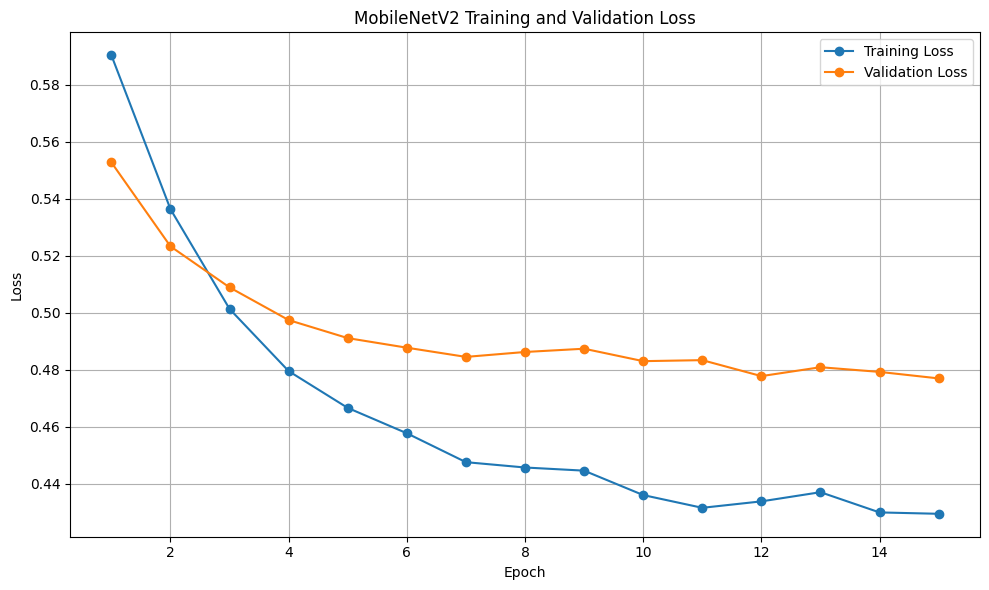

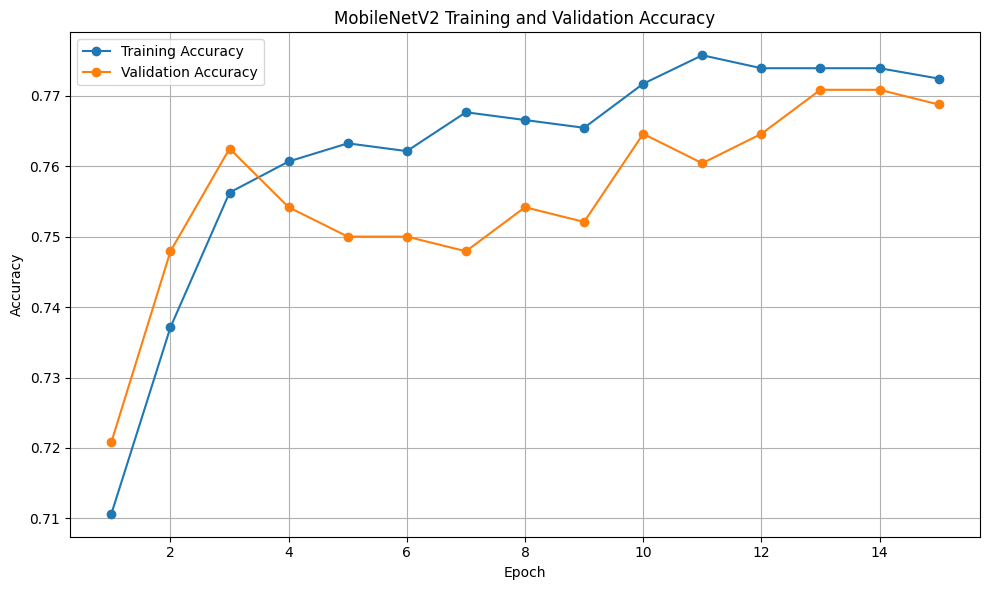

MobileNetV2 TRAINING SUMMARY
Best Epoch           : 15
Best Validation Loss : 0.4769
Validation Accuracy  : 0.7688


In [23]:
# ============================================================
# CELL 13 — MobileNetV2 TRAINING GRAPHS
# ============================================================

epochs_completed_mobilenet = range(
    1,
    len(mobilenet_train_losses) + 1
)


# ============================================================
# 1. LOSS CURVE
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    epochs_completed_mobilenet,
    mobilenet_train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs_completed_mobilenet,
    mobilenet_val_losses,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "MobileNetV2 Training and Validation Loss"
)

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


# ============================================================
# 2. ACCURACY CURVE
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    epochs_completed_mobilenet,
    mobilenet_train_accs,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs_completed_mobilenet,
    mobilenet_val_accs,
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title(
    "MobileNetV2 Training and Validation Accuracy"
)

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


# ============================================================
# 3. BEST VALIDATION RESULT
# ============================================================

best_epoch_mobilenet = (
    np.argmin(mobilenet_val_losses) + 1
)

print("=" * 60)
print("MobileNetV2 TRAINING SUMMARY")
print("=" * 60)

print(
    f"Best Epoch           : "
    f"{best_epoch_mobilenet}"
)

print(
    f"Best Validation Loss : "
    f"{min(mobilenet_val_losses):.4f}"
)

print(
    f"Validation Accuracy  : "
    f"{mobilenet_val_accs[best_epoch_mobilenet - 1]:.4f}"
)

print("=" * 60)

In [24]:
# ============================================================
# CELL 14 — EXTRACT MiT-B2 + FPN FEATURES
# ============================================================

# ------------------------------------------------------------
# Make sure the best MiT-B2 model is loaded
# ------------------------------------------------------------

mit_fpn_model.load_state_dict(
    best_mit_state
)

mit_fpn_model.eval()


# ------------------------------------------------------------
# Feature extraction function
# ------------------------------------------------------------

def extract_mit_features(model, loader, device):

    all_features = []
    all_labels = []

    with torch.no_grad():

        feature_bar = tqdm(
            loader,
            desc="Extracting MiT-B2 + FPN features"
        )

        for images, labels in feature_bar:

            images = images.to(
                device,
                non_blocking=True
            )

            # return_features=True gives:
            # logits, 256-dimensional features
            _, features = model(
                images,
                return_features=True
            )

            all_features.append(
                features.cpu().numpy()
            )

            all_labels.append(
                labels.numpy()
            )

    all_features = np.concatenate(
        all_features,
        axis=0
    )

    all_labels = np.concatenate(
        all_labels,
        axis=0
    )

    return all_features, all_labels


# ============================================================
# Extract TRAIN features
# ============================================================

mit_train_features, mit_train_labels = extract_mit_features(
    mit_fpn_model,
    train_loader,
    device
)


# ============================================================
# Extract VALIDATION features
# ============================================================

mit_val_features, mit_val_labels = extract_mit_features(
    mit_fpn_model,
    val_loader,
    device
)


# ============================================================
# Basic verification
# ============================================================

print("\n" + "=" * 60)
print("MiT-B2 + FPN FEATURE EXTRACTION")
print("=" * 60)

print(
    "Train feature shape:",
    mit_train_features.shape
)

print(
    "Train label shape  :",
    mit_train_labels.shape
)

print(
    "Validation feature shape:",
    mit_val_features.shape
)

print(
    "Validation label shape  :",
    mit_val_labels.shape
)

print("=" * 60)

print("\nExpected:")
print("Train      : (2720, 256)")
print("Validation : (480, 256)")

Extracting MiT-B2 + FPN features:   0%|          | 0/85 [00:00<?, ?it/s]

Extracting MiT-B2 + FPN features:   0%|          | 0/15 [00:00<?, ?it/s]


MiT-B2 + FPN FEATURE EXTRACTION
Train feature shape: (2720, 256)
Train label shape  : (2720,)
Validation feature shape: (480, 256)
Validation label shape  : (480,)

Expected:
Train      : (2720, 256)
Validation : (480, 256)


In [25]:
# ============================================================
# CELL 15 — EXTRACT MobileNetV2 FEATURES
# ============================================================

# ------------------------------------------------------------
# Make sure the BEST fine-tuned MobileNetV2 is loaded
# ------------------------------------------------------------

mobilenet_model.load_state_dict(
    best_mobilenet_state
)

mobilenet_model.eval()


# ------------------------------------------------------------
# Feature extraction function
# ------------------------------------------------------------

def extract_mobilenet_features(model, loader, device):

    all_features = []
    all_labels = []

    with torch.no_grad():

        feature_bar = tqdm(
            loader,
            desc="Extracting MobileNetV2 features"
        )

        for images, labels in feature_bar:

            images = images.to(
                device,
                non_blocking=True
            )

            # ------------------------------------------------
            # MobileNetV2 feature extractor
            #
            # features:
            # [B, 1280, H, W]
            # ------------------------------------------------

            features = model.features(images)

            # ------------------------------------------------
            # Global Average Pooling
            # ------------------------------------------------

            features = F.adaptive_avg_pool2d(
                features,
                (1, 1)
            )

            # ------------------------------------------------
            # Flatten
            # [B, 1280, 1, 1]
            # →
            # [B, 1280]
            # ------------------------------------------------

            features = torch.flatten(
                features,
                start_dim=1
            )

            all_features.append(
                features.cpu().numpy()
            )

            all_labels.append(
                labels.numpy()
            )

    all_features = np.concatenate(
        all_features,
        axis=0
    )

    all_labels = np.concatenate(
        all_labels,
        axis=0
    )

    return all_features, all_labels


# ============================================================
# Extract TRAIN features
# ============================================================

mobilenet_train_features, mobilenet_train_labels = (
    extract_mobilenet_features(
        mobilenet_model,
        train_loader,
        device
    )
)


# ============================================================
# Extract VALIDATION features
# ============================================================

mobilenet_val_features, mobilenet_val_labels = (
    extract_mobilenet_features(
        mobilenet_model,
        val_loader,
        device
    )
)


# ============================================================
# Verification
# ============================================================

print("\n" + "=" * 60)
print("MobileNetV2 FEATURE EXTRACTION")
print("=" * 60)

print(
    "Train feature shape:",
    mobilenet_train_features.shape
)

print(
    "Train label shape  :",
    mobilenet_train_labels.shape
)

print(
    "Validation feature shape:",
    mobilenet_val_features.shape
)

print(
    "Validation label shape  :",
    mobilenet_val_labels.shape
)

print("=" * 60)

print("\nExpected:")
print("Train      : (2720, 1280)")
print("Validation : (480, 1280)")

Extracting MobileNetV2 features:   0%|          | 0/85 [00:00<?, ?it/s]

Extracting MobileNetV2 features:   0%|          | 0/15 [00:00<?, ?it/s]


MobileNetV2 FEATURE EXTRACTION
Train feature shape: (2720, 1280)
Train label shape  : (2720,)
Validation feature shape: (480, 1280)
Validation label shape  : (480,)

Expected:
Train      : (2720, 1280)
Validation : (480, 1280)


In [26]:
# ============================================================
# CELL 16 — CREATE DETERMINISTIC FEATURE LOADERS
# ============================================================

# IMPORTANT:
# train_loader uses shuffle=True for neural-network training.
# For feature fusion, both models MUST see samples in exactly
# the same order.
#
# Therefore we create separate loaders with shuffle=False.

feature_train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

feature_val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Deterministic feature loaders created.")

print("\nTraining loader:")
print("  Shuffle: False")

print("\nValidation loader:")
print("  Shuffle: False")

Deterministic feature loaders created.

Training loader:
  Shuffle: False

Validation loader:
  Shuffle: False


In [27]:
# ============================================================
# CELL 17 — RE-EXTRACT FEATURES WITH IDENTICAL SAMPLE ORDER
# ============================================================

# ============================================================
# 1. MiT-B2 + FPN FEATURES
# ============================================================

mit_fpn_model.load_state_dict(best_mit_state)
mit_fpn_model.eval()

mit_train_features, mit_train_labels = extract_mit_features(
    mit_fpn_model,
    feature_train_loader,
    device
)

mit_val_features, mit_val_labels = extract_mit_features(
    mit_fpn_model,
    feature_val_loader,
    device
)


# ============================================================
# 2. MobileNetV2 FEATURES
# ============================================================

mobilenet_model.load_state_dict(best_mobilenet_state)
mobilenet_model.eval()

mobilenet_train_features, mobilenet_train_labels = (
    extract_mobilenet_features(
        mobilenet_model,
        feature_train_loader,
        device
    )
)

mobilenet_val_features, mobilenet_val_labels = (
    extract_mobilenet_features(
        mobilenet_model,
        feature_val_loader,
        device
    )
)


# ============================================================
# 3. VERIFY LABEL ALIGNMENT
# ============================================================

train_labels_match = np.array_equal(
    mit_train_labels,
    mobilenet_train_labels
)

val_labels_match = np.array_equal(
    mit_val_labels,
    mobilenet_val_labels
)

print("\n" + "=" * 60)
print("FEATURE ALIGNMENT CHECK")
print("=" * 60)

print(
    "Training labels match   :",
    train_labels_match
)

print(
    "Validation labels match :",
    val_labels_match
)


# ============================================================
# 4. HARD SAFETY CHECK
# ============================================================

assert train_labels_match, (
    "ERROR: Training feature labels still do not match."
)

assert val_labels_match, (
    "ERROR: Validation feature labels do not match."
)


# ============================================================
# 5. VERIFY FEATURE SAMPLE COUNTS
# ============================================================

assert (
    mit_train_features.shape[0]
    == mobilenet_train_features.shape[0]
)

assert (
    mit_val_features.shape[0]
    == mobilenet_val_features.shape[0]
)


# ============================================================
# 6. FUSE FEATURES
# ============================================================

fused_train_features = np.concatenate(
    [
        mit_train_features,
        mobilenet_train_features
    ],
    axis=1
)

fused_val_features = np.concatenate(
    [
        mit_val_features,
        mobilenet_val_features
    ],
    axis=1
)


# ============================================================
# 7. FINAL LABELS
# ============================================================

fused_train_labels = mit_train_labels.copy()
fused_val_labels = mit_val_labels.copy()


# ============================================================
# 8. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 60)
print("FEATURE FUSION COMPLETE")
print("=" * 60)

print(
    "MiT-B2 + FPN train features :",
    mit_train_features.shape
)

print(
    "MobileNetV2 train features  :",
    mobilenet_train_features.shape
)

print(
    "Fused train features        :",
    fused_train_features.shape
)

print(
    "Fused validation features   :",
    fused_val_features.shape
)

print(
    "Training labels             :",
    fused_train_labels.shape
)

print(
    "Validation labels           :",
    fused_val_labels.shape
)

print("=" * 60)

Extracting MiT-B2 + FPN features:   0%|          | 0/85 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e421c447420>
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e421c447420>Traceback (most recent call last):

  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
        self._shutdown_workers()self._shutdown_workers()

  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
        if w.is_alive():
if w.is_alive():
              ^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
^
      File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
assert self._par

Extracting MiT-B2 + FPN features:   0%|          | 0/15 [00:00<?, ?it/s]

Extracting MobileNetV2 features:   0%|          | 0/85 [00:00<?, ?it/s]

Extracting MobileNetV2 features:   0%|          | 0/15 [00:00<?, ?it/s]


FEATURE ALIGNMENT CHECK
Training labels match   : True
Validation labels match : True

FEATURE FUSION COMPLETE
MiT-B2 + FPN train features : (2720, 256)
MobileNetV2 train features  : (2720, 1280)
Fused train features        : (2720, 1536)
Fused validation features   : (480, 1536)
Training labels             : (2720,)
Validation labels           : (480,)


In [28]:
# ============================================================
# CELL 18 — STANDARDIZE FUSED FEATURES
# ============================================================

# ------------------------------------------------------------
# Create scaler
# ------------------------------------------------------------

feature_scaler = StandardScaler()


# ------------------------------------------------------------
# FIT ONLY ON TRAINING FEATURES
# ------------------------------------------------------------

fused_train_features_scaled = feature_scaler.fit_transform(
    fused_train_features
)


# ------------------------------------------------------------
# TRANSFORM VALIDATION FEATURES
# DO NOT FIT AGAIN
# ------------------------------------------------------------

fused_val_features_scaled = feature_scaler.transform(
    fused_val_features
)


# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

print("=" * 60)
print("FEATURE STANDARDIZATION COMPLETE")
print("=" * 60)

print(
    "Original train shape :",
    fused_train_features.shape
)

print(
    "Scaled train shape   :",
    fused_train_features_scaled.shape
)

print(
    "Original val shape   :",
    fused_val_features.shape
)

print(
    "Scaled val shape     :",
    fused_val_features_scaled.shape
)


# ------------------------------------------------------------
# Check training statistics
# ------------------------------------------------------------

print("\nTraining feature statistics:")

print(
    "Mean (first 5 features):",
    np.mean(
        fused_train_features_scaled[:, :5],
        axis=0
    )
)

print(
    "Std  (first 5 features):",
    np.std(
        fused_train_features_scaled[:, :5],
        axis=0
    )
)

print("=" * 60)

print("\n✓ Scaler fitted only on training data.")
print("✓ Validation data transformed using the same scaler.")

FEATURE STANDARDIZATION COMPLETE
Original train shape : (2720, 1536)
Scaled train shape   : (2720, 1536)
Original val shape   : (480, 1536)
Scaled val shape     : (480, 1536)

Training feature statistics:
Mean (first 5 features): [-5.8947243e-09 -6.0262049e-09 -4.2731272e-09 -5.5441083e-09
  1.4813507e-08]
Std  (first 5 features): [1.0000004  0.9999999  1.0000002  0.99999994 0.9999998 ]

✓ Scaler fitted only on training data.
✓ Validation data transformed using the same scaler.


In [29]:
# ============================================================
# CELL 19 — RANDOM FOREST
# ============================================================

# ------------------------------------------------------------
# Create Random Forest
# ------------------------------------------------------------

rf_model = RandomForestClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1
)


# ------------------------------------------------------------
# Train Random Forest
# ------------------------------------------------------------

print("Training Random Forest...")

rf_model.fit(
    fused_train_features_scaled,
    fused_train_labels
)

print("✓ Random Forest training complete.")


# ------------------------------------------------------------
# Validation predictions
# ------------------------------------------------------------

rf_val_predictions = rf_model.predict(
    fused_val_features_scaled
)

rf_val_probabilities = rf_model.predict_proba(
    fused_val_features_scaled
)[:, 1]


# ------------------------------------------------------------
# Validation metrics
# ------------------------------------------------------------

rf_val_accuracy = accuracy_score(
    fused_val_labels,
    rf_val_predictions
)

rf_val_precision = precision_score(
    fused_val_labels,
    rf_val_predictions,
    zero_division=0
)

rf_val_recall = recall_score(
    fused_val_labels,
    rf_val_predictions,
    zero_division=0
)

rf_val_f1 = f1_score(
    fused_val_labels,
    rf_val_predictions,
    zero_division=0
)

rf_val_auc = roc_auc_score(
    fused_val_labels,
    rf_val_probabilities
)


# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("RANDOM FOREST — VALIDATION RESULTS")
print("=" * 60)

print(f"Accuracy : {rf_val_accuracy:.4f}")
print(f"Precision: {rf_val_precision:.4f}")
print(f"Recall   : {rf_val_recall:.4f}")
print(f"F1-score : {rf_val_f1:.4f}")
print(f"ROC-AUC  : {rf_val_auc:.4f}")

print("=" * 60)


# ------------------------------------------------------------
# Classification report
# ------------------------------------------------------------

print("\nClassification Report:")
print(
    classification_report(
        fused_val_labels,
        rf_val_predictions,
        target_names=class_names,
        zero_division=0
    )
)

Training Random Forest...
✓ Random Forest training complete.

RANDOM FOREST — VALIDATION RESULTS
Accuracy : 0.7792
Precision: 0.7959
Recall   : 0.2889
F1-score : 0.4239
ROC-AUC  : 0.7881

Classification Report:
                  precision    recall  f1-score   support

Appears abnormal       0.78      0.97      0.86       345
  Appears normal       0.80      0.29      0.42       135

        accuracy                           0.78       480
       macro avg       0.79      0.63      0.64       480
    weighted avg       0.78      0.78      0.74       480



In [ ]:
# ============================================================
# CELL 20 — K-NEAREST NEIGHBORS (KNN)
# ============================================================

# ------------------------------------------------------------
# Create KNN classifier
# ------------------------------------------------------------

knn_model = KNeighborsClassifier(
    n_neighbors=5,
    weights="distance",
    metric="euclidean",
    n_jobs=-1
)


# ------------------------------------------------------------
# Train KNN
# ------------------------------------------------------------

print("Training KNN...")

knn_model.fit(
    fused_train_features_scaled,
    fused_train_labels
)

print("✓ KNN training complete.")


# ------------------------------------------------------------
# Validation predictions
# ------------------------------------------------------------

knn_val_predictions = knn_model.predict(
    fused_val_features_scaled
)

knn_val_probabilities = knn_model.predict_proba(
    fused_val_features_scaled
)[:, 1]


# ------------------------------------------------------------
# Validation metrics
# ------------------------------------------------------------

knn_val_accuracy = accuracy_score(
    fused_val_labels,
    knn_val_predictions
)

knn_val_precision = precision_score(
    fused_val_labels,
    knn_val_predictions,
    zero_division=0
)

knn_val_recall = recall_score(
    fused_val_labels,
    knn_val_predictions,
    zero_division=0
)

knn_val_f1 = f1_score(
    fused_val_labels,
    knn_val_predictions,
    zero_division=0
)

knn_val_auc = roc_auc_score(
    fused_val_labels,
    knn_val_probabilities
)


# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("KNN — VALIDATION RESULTS")
print("=" * 60)

print(f"Accuracy : {knn_val_accuracy:.4f}")
print(f"Precision: {knn_val_precision:.4f}")
print(f"Recall   : {knn_val_recall:.4f}")
print(f"F1-score : {knn_val_f1:.4f}")
print(f"ROC-AUC  : {knn_val_auc:.4f}")

print("=" * 60)


# ------------------------------------------------------------
# Classification report
# ------------------------------------------------------------

print("\nClassification Report:")

print(
    classification_report(
        fused_val_labels,
        knn_val_predictions,
        target_names=class_names,
        zero_division=0
    )
)

In [ ]:
# ============================================================
# CELL 21 — NAIVE BAYES
# ============================================================

# ------------------------------------------------------------
# Create Gaussian Naive Bayes
# ------------------------------------------------------------

nb_model = GaussianNB()


# ------------------------------------------------------------
# Train Naive Bayes
# ------------------------------------------------------------

print("Training Naive Bayes...")

nb_model.fit(
    fused_train_features_scaled,
    fused_train_labels
)

print("✓ Naive Bayes training complete.")


# ------------------------------------------------------------
# Validation predictions
# ------------------------------------------------------------

nb_val_predictions = nb_model.predict(
    fused_val_features_scaled
)

nb_val_probabilities = nb_model.predict_proba(
    fused_val_features_scaled
)[:, 1]


# ------------------------------------------------------------
# Validation metrics
# ------------------------------------------------------------

nb_val_accuracy = accuracy_score(
    fused_val_labels,
    nb_val_predictions
)

nb_val_precision = precision_score(
    fused_val_labels,
    nb_val_predictions,
    zero_division=0
)

nb_val_recall = recall_score(
    fused_val_labels,
    nb_val_predictions,
    zero_division=0
)

nb_val_f1 = f1_score(
    fused_val_labels,
    nb_val_predictions,
    zero_division=0
)

nb_val_auc = roc_auc_score(
    fused_val_labels,
    nb_val_probabilities
)


# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("NAIVE BAYES — VALIDATION RESULTS")
print("=" * 60)

print(f"Accuracy : {nb_val_accuracy:.4f}")
print(f"Precision: {nb_val_precision:.4f}")
print(f"Recall   : {nb_val_recall:.4f}")
print(f"F1-score : {nb_val_f1:.4f}")
print(f"ROC-AUC  : {nb_val_auc:.4f}")

print("=" * 60)


# ------------------------------------------------------------
# Classification report
# ------------------------------------------------------------

print("\nClassification Report:")

print(
    classification_report(
        fused_val_labels,
        nb_val_predictions,
        target_names=class_names,
        zero_division=0
    )
)

In [ ]:
# ============================================================
# CELL 22 — ADABOOST
# ============================================================

# ------------------------------------------------------------
# Create AdaBoost classifier
# ------------------------------------------------------------

adaboost_model = AdaBoostClassifier(
    n_estimators=300,
    learning_rate=0.05,
    random_state=SEED
)


# ------------------------------------------------------------
# Train AdaBoost
# ------------------------------------------------------------

print("Training AdaBoost...")

adaboost_model.fit(
    fused_train_features_scaled,
    fused_train_labels
)

print("✓ AdaBoost training complete.")


# ------------------------------------------------------------
# Validation predictions
# ------------------------------------------------------------

adaboost_val_predictions = adaboost_model.predict(
    fused_val_features_scaled
)

adaboost_val_probabilities = (
    adaboost_model.predict_proba(
        fused_val_features_scaled
    )[:, 1]
)


# ------------------------------------------------------------
# Validation metrics
# ------------------------------------------------------------

adaboost_val_accuracy = accuracy_score(
    fused_val_labels,
    adaboost_val_predictions
)

adaboost_val_precision = precision_score(
    fused_val_labels,
    adaboost_val_predictions,
    zero_division=0
)

adaboost_val_recall = recall_score(
    fused_val_labels,
    adaboost_val_predictions,
    zero_division=0
)

adaboost_val_f1 = f1_score(
    fused_val_labels,
    adaboost_val_predictions,
    zero_division=0
)

adaboost_val_auc = roc_auc_score(
    fused_val_labels,
    adaboost_val_probabilities
)


# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("ADABOOST — VALIDATION RESULTS")
print("=" * 60)

print(f"Accuracy : {adaboost_val_accuracy:.4f}")
print(f"Precision: {adaboost_val_precision:.4f}")
print(f"Recall   : {adaboost_val_recall:.4f}")
print(f"F1-score : {adaboost_val_f1:.4f}")
print(f"ROC-AUC  : {adaboost_val_auc:.4f}")

print("=" * 60)


# ------------------------------------------------------------
# Classification report
# ------------------------------------------------------------

print("\nClassification Report:")

print(
    classification_report(
        fused_val_labels,
        adaboost_val_predictions,
        target_names=class_names,
        zero_division=0
    )
)

In [ ]:
# ============================================================
# CELL 23 — VALIDATION COMPARISON
# ============================================================

validation_results = pd.DataFrame({

    "Classifier": [
        "Random Forest",
        "KNN",
        "Naive Bayes",
        "AdaBoost"
    ],

    "Accuracy": [
        rf_val_accuracy,
        knn_val_accuracy,
        nb_val_accuracy,
        adaboost_val_accuracy
    ],

    "Precision": [
        rf_val_precision,
        knn_val_precision,
        nb_val_precision,
        adaboost_val_precision
    ],

    "Recall": [
        rf_val_recall,
        knn_val_recall,
        nb_val_recall,
        adaboost_val_recall
    ],

    "F1-score": [
        rf_val_f1,
        knn_val_f1,
        nb_val_f1,
        adaboost_val_f1
    ],

    "ROC-AUC": [
        rf_val_auc,
        knn_val_auc,
        nb_val_auc,
        adaboost_val_auc
    ]
})


# ------------------------------------------------------------
# Display table
# ------------------------------------------------------------

print("=" * 80)
print("VALIDATION PERFORMANCE — FUSED FEATURES")
print("=" * 80)

display(
    validation_results.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)


# ------------------------------------------------------------
# Bar chart — Validation Accuracy
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.bar(
    validation_results["Classifier"],
    validation_results["Accuracy"]
)

plt.xlabel("Classifier")
plt.ylabel("Accuracy")
plt.title(
    "Validation Accuracy — MiT-B2 + FPN + MobileNetV2 Fusion"
)

plt.ylim(0, 1.0)
plt.xticks(rotation=15)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Bar chart — All Metrics
# ------------------------------------------------------------

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC"
]

x = np.arange(
    len(validation_results["Classifier"])
)

width = 0.15

plt.figure(figsize=(14, 7))

for i, metric in enumerate(metrics):

    plt.bar(
        x + (i - 2) * width,
        validation_results[metric],
        width=width,
        label=metric
    )

plt.xlabel("Classifier")
plt.ylabel("Score")
plt.title(
    "Validation Metrics — Fused Deep Features"
)

plt.xticks(
    x,
    validation_results["Classifier"],
    rotation=15
)

plt.ylim(0, 1.0)

plt.legend()
plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# CELL 24 — EXTRACT TEST FEATURES
# ============================================================

# ------------------------------------------------------------
# Create deterministic test feature loader
# ------------------------------------------------------------

feature_test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


# ============================================================
# 1. MiT-B2 + FPN TEST FEATURES
# ============================================================

mit_fpn_model.load_state_dict(
    best_mit_state
)

mit_fpn_model.eval()

mit_test_features, mit_test_labels = extract_mit_features(
    mit_fpn_model,
    feature_test_loader,
    device
)


# ============================================================
# 2. MobileNetV2 TEST FEATURES
# ============================================================

mobilenet_model.load_state_dict(
    best_mobilenet_state
)

mobilenet_model.eval()

mobilenet_test_features, mobilenet_test_labels = (
    extract_mobilenet_features(
        mobilenet_model,
        feature_test_loader,
        device
    )
)


# ============================================================
# 3. VERIFY LABEL ALIGNMENT
# ============================================================

test_labels_match = np.array_equal(
    mit_test_labels,
    mobilenet_test_labels
)

print("\n" + "=" * 60)
print("TEST FEATURE ALIGNMENT")
print("=" * 60)

print(
    "Test labels match:",
    test_labels_match
)


# ------------------------------------------------------------
# Safety check
# ------------------------------------------------------------

assert test_labels_match, (
    "ERROR: MiT-B2 and MobileNetV2 test "
    "labels are not aligned."
)


# ============================================================
# 4. FUSE TEST FEATURES
# ============================================================

fused_test_features = np.concatenate(
    [
        mit_test_features,
        mobilenet_test_features
    ],
    axis=1
)

fused_test_labels = mit_test_labels.copy()


# ============================================================
# 5. APPLY THE EXISTING SCALER
# ============================================================
#
# IMPORTANT:
# We DO NOT fit a new scaler on the test set.
# The scaler was fitted only on training features in Cell 18.
# ------------------------------------------------------------

fused_test_features_scaled = feature_scaler.transform(
    fused_test_features
)


# ============================================================
# 6. VERIFY SHAPES
# ============================================================

print("\n" + "=" * 60)
print("TEST FEATURE EXTRACTION COMPLETE")
print("=" * 60)

print(
    "MiT-B2 + FPN test features :",
    mit_test_features.shape
)

print(
    "MobileNetV2 test features  :",
    mobilenet_test_features.shape
)

print(
    "Fused test features        :",
    fused_test_features.shape
)

print(
    "Scaled test features       :",
    fused_test_features_scaled.shape
)

print(
    "Test labels                :",
    fused_test_labels.shape
)

print("=" * 60)

In [ ]:
# ============================================================
# CELL 25 — RANDOM FOREST FINAL TEST EVALUATION
# ============================================================

# ------------------------------------------------------------
# Test predictions
# ------------------------------------------------------------

rf_test_predictions = rf_model.predict(
    fused_test_features_scaled
)

rf_test_probabilities = rf_model.predict_proba(
    fused_test_features_scaled
)[:, 1]


# ------------------------------------------------------------
# Calculate metrics
# ------------------------------------------------------------

rf_test_accuracy = accuracy_score(
    fused_test_labels,
    rf_test_predictions
)

rf_test_precision = precision_score(
    fused_test_labels,
    rf_test_predictions,
    zero_division=0
)

rf_test_recall = recall_score(
    fused_test_labels,
    rf_test_predictions,
    zero_division=0
)

rf_test_f1 = f1_score(
    fused_test_labels,
    rf_test_predictions,
    zero_division=0
)

rf_test_auc = roc_auc_score(
    fused_test_labels,
    rf_test_probabilities
)


# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("=" * 60)
print("RANDOM FOREST — FINAL TEST RESULTS")
print("=" * 60)

print(f"Test Accuracy : {rf_test_accuracy:.4f}")
print(f"Test Precision: {rf_test_precision:.4f}")
print(f"Test Recall   : {rf_test_recall:.4f}")
print(f"Test F1-score : {rf_test_f1:.4f}")
print(f"Test ROC-AUC  : {rf_test_auc:.4f}")

print("=" * 60)


# ------------------------------------------------------------
# Classification report
# ------------------------------------------------------------

print("\nClassification Report:")

print(
    classification_report(
        fused_test_labels,
        rf_test_predictions,
        target_names=class_names,
        zero_division=0
    )
)

In [ ]:
# ============================================================
# CELL 26 — FIXED DETERMINISTIC FEATURE EXTRACTION
# ============================================================

# ------------------------------------------------------------
# Find the trained MiT-B2 model automatically
# ------------------------------------------------------------

mit_model = None

# Check common variable names first
for name in ["mit_model", "model_mit", "mit_fpn_model"]:
    if name in globals() and isinstance(globals()[name], nn.Module):
        mit_model = globals()[name]
        print(f"Using MiT model variable: {name}")
        break

# If not found, search by model class
if mit_model is None:
    for name, obj in globals().items():
        if isinstance(obj, MiTB2_FPN_Classifier):
            mit_model = obj
            print(f"Found MiT model automatically: {name}")
            break

if mit_model is None:
    raise RuntimeError(
        "MiT-B2 model was not found. Please rerun the MiT-B2 model definition cell."
    )


# ------------------------------------------------------------
# Load best MiT weights
# ------------------------------------------------------------

mit_model.load_state_dict(best_mit_state)
mit_model.to(device)
mit_model.eval()


# ------------------------------------------------------------
# Deterministic feature dataset
# ------------------------------------------------------------

feature_train_dataset = TransformSubset(
    full_train_dataset,
    train_indices,
    transform=eval_transform
)

feature_train_loader = DataLoader(
    feature_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


# ============================================================
# MiT-B2 FEATURES
# ============================================================

print("Extracting deterministic MiT-B2 train features...")

mit_train_features, mit_train_labels = extract_mit_features(
    mit_model,
    feature_train_loader,
    device
)


# ============================================================
# MOBILENETV2 FEATURES
# ============================================================

mobilenet_model.load_state_dict(best_mobilenet_state)
mobilenet_model.to(device)
mobilenet_model.eval()

print("Extracting deterministic MobileNetV2 train features...")

mobilenet_train_features, mobilenet_train_labels = extract_mobilenet_features(
    mobilenet_model,
    feature_train_loader,
    device
)


# ============================================================
# VERIFY LABEL ALIGNMENT
# ============================================================

print("\nLabel alignment check:")

print(
    "MiT == MobileNet:",
    np.array_equal(
        mit_train_labels,
        mobilenet_train_labels
    )
)

print(
    "MiT == Original:",
    np.array_equal(
        mit_train_labels,
        train_labels
    )
)

assert np.array_equal(
    mit_train_labels,
    mobilenet_train_labels
)

assert np.array_equal(
    mit_train_labels,
    train_labels
)


# ============================================================
# FUSE FEATURES
# ============================================================

fused_train_features = np.concatenate(
    [
        mit_train_features,
        mobilenet_train_features
    ],
    axis=1
)

fused_train_labels = mit_train_labels.copy()


# ============================================================
# PRINT RESULTS
# ============================================================

print("\nFeature shapes:")
print("MiT-B2       :", mit_train_features.shape)
print("MobileNetV2  :", mobilenet_train_features.shape)
print("Fused        :", fused_train_features.shape)
print("Labels       :", fused_train_labels.shape)

print("\nDeterministic feature extraction completed successfully.")

In [ ]:
# ============================================================
# CELL 27 — SCALE FEATURES + TRAIN ALL CLASSIFIERS
# ============================================================

# ------------------------------------------------------------
# 1. Standardize fused features
# ------------------------------------------------------------

feature_scaler = StandardScaler()

# Fit ONLY on training features
fused_train_features_scaled = feature_scaler.fit_transform(
    fused_train_features
)

# Transform validation and test using the SAME scaler
fused_val_features_scaled = feature_scaler.transform(
    fused_val_features
)

fused_test_features_scaled = feature_scaler.transform(
    fused_test_features
)

print("Scaled feature shapes:")
print("Train:", fused_train_features_scaled.shape)
print("Val  :", fused_val_features_scaled.shape)
print("Test :", fused_test_features_scaled.shape)


# ============================================================
# 2. RANDOM FOREST
# ============================================================

print("\nTraining Random Forest...")

rf_model = RandomForestClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1
)

rf_model.fit(
    fused_train_features_scaled,
    fused_train_labels
)

print("Random Forest trained.")


# ============================================================
# 3. KNN
# ============================================================

print("\nTraining KNN...")

knn_model = KNeighborsClassifier(
    n_neighbors=5,
    weights="distance",
    metric="euclidean",
    n_jobs=-1
)

knn_model.fit(
    fused_train_features_scaled,
    fused_train_labels
)

print("KNN trained.")


# ============================================================
# 4. GAUSSIAN NAIVE BAYES
# ============================================================

print("\nTraining Gaussian Naive Bayes...")

nb_model = GaussianNB()

nb_model.fit(
    fused_train_features_scaled,
    fused_train_labels
)

print("Gaussian Naive Bayes trained.")


# ============================================================
# 5. ADABOOST
# ============================================================

print("\nTraining AdaBoost...")

adaboost_model = AdaBoostClassifier(
    n_estimators=300,
    learning_rate=0.05,
    random_state=SEED
)

adaboost_model.fit(
    fused_train_features_scaled,
    fused_train_labels
)

print("AdaBoost trained.")


# ============================================================
# FINAL CHECK
# ============================================================

print("\n" + "=" * 60)
print("ALL CLASSIFIERS TRAINED SUCCESSFULLY")
print("=" * 60)

print("Random Forest       : READY")
print("KNN                 : READY")
print("Gaussian Naive Bayes: READY")
print("AdaBoost            : READY")

In [ ]:
# ============================================================
# CELL 28 — FINAL TEST EVALUATION + CONFUSION MATRICES
# ============================================================

def evaluate_classifier(model, model_name):

    predictions = model.predict(fused_test_features_scaled)

    if hasattr(model, "predict_proba"):
        probabilities = model.predict_proba(
            fused_test_features_scaled
        )[:, 1]
    else:
        probabilities = None

    accuracy = accuracy_score(
        test_labels,
        predictions
    )

    precision = precision_score(
        test_labels,
        predictions,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        test_labels,
        predictions,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        test_labels,
        predictions,
        average="weighted",
        zero_division=0
    )

    if probabilities is not None:
        roc_auc = roc_auc_score(
            test_labels,
            probabilities
        )
    else:
        roc_auc = np.nan

    # --------------------------------------------------------
    # Confusion Matrix
    # --------------------------------------------------------

    cm = confusion_matrix(
        test_labels,
        predictions
    )

    print("\n" + "=" * 65)
    print(f"{model_name} — FINAL TEST RESULTS")
    print("=" * 65)

    print(f"Test Accuracy : {accuracy:.4f}")
    print(f"Test Precision: {precision:.4f}")
    print(f"Test Recall   : {recall:.4f}")
    print(f"Test F1-score : {f1:.4f}")
    print(f"Test ROC-AUC  : {roc_auc:.4f}")

    print("\nConfusion Matrix:")
    print(cm)

    print("\nClassification Report:")
    print(
        classification_report(
            test_labels,
            predictions,
            target_names=test_dataset.classes,
            digits=4,
            zero_division=0
        )
    )

    # --------------------------------------------------------
    # Plot Confusion Matrix
    # --------------------------------------------------------

    plt.figure(figsize=(6, 5))

    plt.imshow(cm)

    plt.title(f"{model_name} — Confusion Matrix")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")

    plt.xticks(
        [0, 1],
        test_dataset.classes,
        rotation=20
    )

    plt.yticks(
        [0, 1],
        test_dataset.classes
    )

    # Add numbers inside matrix
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            plt.text(
                j,
                i,
                cm[i, j],
                ha="center",
                va="center",
                fontsize=14
            )

    plt.colorbar()
    plt.tight_layout()
    plt.show()

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "ROC-AUC": roc_auc,
        "Confusion Matrix": cm
    }


# ============================================================
# EVALUATE ALL FOUR CLASSIFIERS
# ============================================================

rf_results = evaluate_classifier(
    rf_model,
    "Random Forest"
)

knn_results = evaluate_classifier(
    knn_model,
    "KNN"
)

nb_results = evaluate_classifier(
    nb_model,
    "Gaussian Naive Bayes"
)

adaboost_results = evaluate_classifier(
    adaboost_model,
    "AdaBoost"
)


# ============================================================
# FINAL COMPARISON TABLE
# ============================================================

final_results = pd.DataFrame([
    rf_results,
    knn_results,
    nb_results,
    adaboost_results
])

# Remove confusion matrix from displayed comparison table
comparison_table = final_results[
    [
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ]
]

print("\n")
print("=" * 80)
print("FINAL TEST COMPARISON")
print("=" * 80)

display(
    comparison_table.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)

# NB

Loading weights:   0%|          | 0/364 [00:00<?, ?it/s]

SegformerModel LOAD REPORT from: nvidia/mit-b2
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loaded newly retrained MiT-B2.

Extracting NEW MiT train features...
Extracting NEW MiT validation features...
Extracting NEW MiT test features...

Loaded best MobileNetV2.

Extracting MobileNet train features...


Extracting MobileNetV2 features:   0%|          | 0/85 [00:00<?, ?it/s]

Extracting MobileNet validation features...


Extracting MobileNetV2 features:   0%|          | 0/15 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e421c447420>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e421c447420>    
if w.is_alive():
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
      self._shutdown_workers()
    File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
     if w.is_alive():  ^
^  ^  ^ ^^ ^^^ ^^^^^^^
^^  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
^    assert self._parent_pid == os.getpid(), 'can only test a child process'^^
  ^  ^^
   File "/usr/lib/p

Extracting MobileNet test features...


Extracting MobileNetV2 features:   0%|          | 0/46 [00:00<?, ?it/s]


MobileNet feature extraction completed.

FEATURE SHAPES
MiT train       : (2720, 256)
MiT validation  : (480, 256)
MiT test        : (1468, 256)
MobileNet train : (2720, 1280)
MobileNet val   : (480, 1280)
MobileNet test  : (1468, 1280)

Checking label alignment...
Label alignment: PASSED

Fused feature shapes:
Train: (2720, 1536)
Val  : (480, 1536)
Test : (1468, 1536)

Feature scaling completed.

GAUSSIAN NAIVE BAYES — VALIDATION SEARCH
var_smoothing = 1e-11 | Validation Accuracy = 0.5813
var_smoothing = 1e-10 | Validation Accuracy = 0.5813
var_smoothing = 1e-09 | Validation Accuracy = 0.5813
var_smoothing = 1e-08 | Validation Accuracy = 0.5813
var_smoothing = 1e-07 | Validation Accuracy = 0.5813
var_smoothing = 1e-06 | Validation Accuracy = 0.5813
var_smoothing = 1e-05 | Validation Accuracy = 0.5813
var_smoothing = 1e-04 | Validation Accuracy = 0.5813
var_smoothing = 1e-03 | Validation Accuracy = 0.5813
var_smoothing = 1e-02 | Validation Accuracy = 0.5833
var_smoothing = 1e-01 | Val

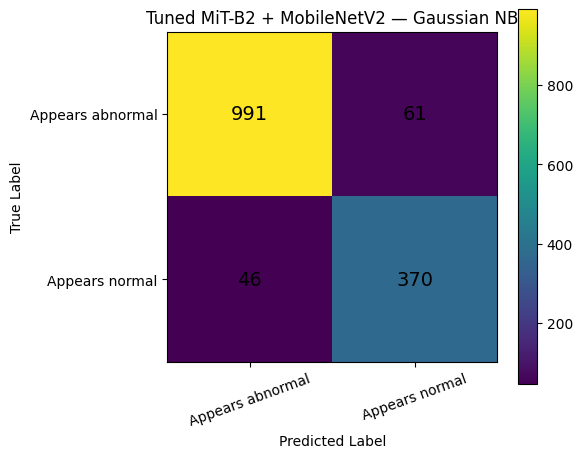

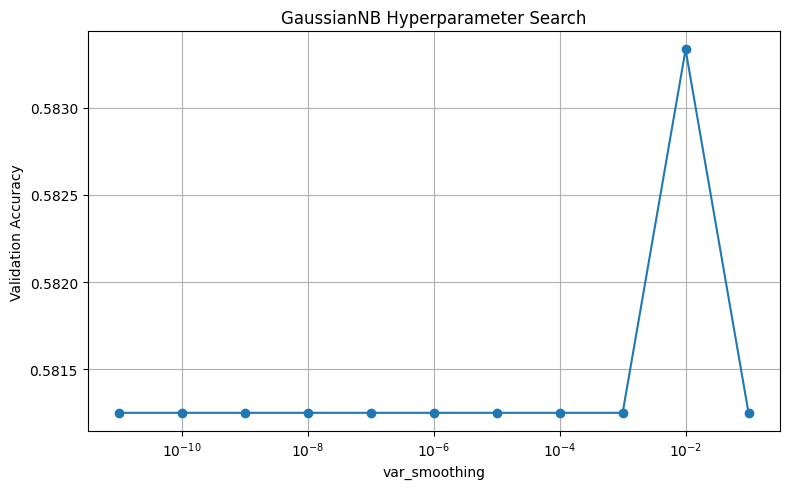

In [33]:
# ============================================================
# TUNED MiT-B2 + MobileNetV2 → GAUSSIAN NAIVE BAYES
# FULL CORRECTED CODE
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)


# ============================================================
# 1. DETERMINISTIC DATASET SUBSET
# ============================================================

class NBFeatureSubset(Dataset):

    def __init__(self, dataset, indices, transform):
        self.dataset = dataset
        self.indices = list(indices)
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):

        image, label = self.dataset[self.indices[idx]]

        if self.transform is not None:
            image = self.transform(image)

        return image, label


# ============================================================
# 2. CREATE DETERMINISTIC LOADERS
# ============================================================

nb_train_dataset = NBFeatureSubset(
    full_train_dataset,
    train_indices,
    eval_transform
)

nb_val_dataset = NBFeatureSubset(
    full_train_dataset,
    val_indices,
    eval_transform
)

nb_train_loader = DataLoader(
    nb_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

nb_val_loader = DataLoader(
    nb_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

nb_test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


# ============================================================
# 3. LOAD NEWLY TRAINED MiT-B2
# ============================================================

model_mit = MiTB2_FPN_Classifier(
    num_classes=2,
    fpn_channels=256
).to(device)

model_mit.load_state_dict(best_mit_state)
model_mit.eval()

print("Loaded newly retrained MiT-B2.")


# ============================================================
# 4. MiT FEATURE EXTRACTION FUNCTION
# ============================================================

def extract_mit_nb_features(model, loader, device):

    features = []
    labels = []

    model.eval()

    with torch.no_grad():

        for images, batch_labels in loader:

            images = images.to(
                device,
                non_blocking=True
            )

            _, batch_features = model(
                images,
                return_features=True
            )

            features.append(
                batch_features.cpu().numpy()
            )

            labels.append(
                batch_labels.numpy()
            )

    return (
        np.concatenate(features, axis=0),
        np.concatenate(labels, axis=0)
    )


# ============================================================
# 5. EXTRACT NEW MiT FEATURES
# ============================================================

print("\nExtracting NEW MiT train features...")

mit_train_nb, train_nb_labels = extract_mit_nb_features(
    model_mit,
    nb_train_loader,
    device
)

print("Extracting NEW MiT validation features...")

mit_val_nb, val_nb_labels = extract_mit_nb_features(
    model_mit,
    nb_val_loader,
    device
)

print("Extracting NEW MiT test features...")

mit_test_nb, test_nb_labels = extract_mit_nb_features(
    model_mit,
    nb_test_loader,
    device
)


# ============================================================
# 6. LOAD BEST MOBILENETV2
# ============================================================

mobilenet_model.load_state_dict(
    best_mobilenet_state
)

mobilenet_model.to(device)
mobilenet_model.eval()

print("\nLoaded best MobileNetV2.")


# ============================================================
# 7. MOBILE NET FEATURE EXTRACTION
# ============================================================

print("\nExtracting MobileNet train features...")

mobile_train_nb, mobile_train_labels_nb = extract_mobilenet_features(
    mobilenet_model,
    nb_train_loader,
    device
)

print("Extracting MobileNet validation features...")

mobile_val_nb, mobile_val_labels_nb = extract_mobilenet_features(
    mobilenet_model,
    nb_val_loader,
    device
)

print("Extracting MobileNet test features...")

mobile_test_nb, mobile_test_labels_nb = extract_mobilenet_features(
    mobilenet_model,
    nb_test_loader,
    device
)

print("\nMobileNet feature extraction completed.")


# ============================================================
# 8. FEATURE SHAPES
# ============================================================

print("\n" + "=" * 60)
print("FEATURE SHAPES")
print("=" * 60)

print("MiT train       :", mit_train_nb.shape)
print("MiT validation  :", mit_val_nb.shape)
print("MiT test        :", mit_test_nb.shape)

print("MobileNet train :", mobile_train_nb.shape)
print("MobileNet val   :", mobile_val_nb.shape)
print("MobileNet test  :", mobile_test_nb.shape)


# ============================================================
# 9. VERIFY LABEL ALIGNMENT
# ============================================================

print("\nChecking label alignment...")

assert np.array_equal(
    train_nb_labels,
    mobile_train_labels_nb
)

assert np.array_equal(
    val_nb_labels,
    mobile_val_labels_nb
)

assert np.array_equal(
    test_nb_labels,
    mobile_test_labels_nb
)

print("Label alignment: PASSED")


# ============================================================
# 10. FUSE MiT + MOBILE NET FEATURES
# ============================================================

X_train_fused = np.concatenate(
    [
        mit_train_nb,
        mobile_train_nb
    ],
    axis=1
)

X_val_fused = np.concatenate(
    [
        mit_val_nb,
        mobile_val_nb
    ],
    axis=1
)

X_test_fused = np.concatenate(
    [
        mit_test_nb,
        mobile_test_nb
    ],
    axis=1
)

print("\nFused feature shapes:")

print("Train:", X_train_fused.shape)
print("Val  :", X_val_fused.shape)
print("Test :", X_test_fused.shape)


# ============================================================
# 11. STANDARD SCALING
# ============================================================

nb_scaler = StandardScaler()

X_train_scaled = nb_scaler.fit_transform(
    X_train_fused
)

X_val_scaled = nb_scaler.transform(
    X_val_fused
)

X_test_scaled = nb_scaler.transform(
    X_test_fused
)

print("\nFeature scaling completed.")


# ============================================================
# 12. GAUSSIAN NB HYPERPARAMETER SEARCH
# ============================================================

var_smoothing_values = [
    1e-11,
    1e-10,
    1e-9,
    1e-8,
    1e-7,
    1e-6,
    1e-5,
    1e-4,
    1e-3,
    1e-2,
    1e-1
]

nb_validation_results = []

print("\n" + "=" * 65)
print("GAUSSIAN NAIVE BAYES — VALIDATION SEARCH")
print("=" * 65)

for smoothing in var_smoothing_values:

    model = GaussianNB(
        var_smoothing=smoothing
    )

    model.fit(
        X_train_scaled,
        train_nb_labels
    )

    val_predictions = model.predict(
        X_val_scaled
    )

    val_accuracy = accuracy_score(
        val_nb_labels,
        val_predictions
    )

    nb_validation_results.append({
        "var_smoothing": smoothing,
        "Validation Accuracy": val_accuracy
    })

    print(
        f"var_smoothing = {smoothing:.0e} "
        f"| Validation Accuracy = {val_accuracy:.4f}"
    )


# ============================================================
# 13. FIND BEST PARAMETER
# ============================================================

nb_validation_results = pd.DataFrame(
    nb_validation_results
)

best_row = nb_validation_results.loc[
    nb_validation_results["Validation Accuracy"].idxmax()
]

best_var_smoothing = best_row["var_smoothing"]
best_val_accuracy = best_row["Validation Accuracy"]

print("\n" + "=" * 65)
print("BEST GaussianNB PARAMETER")
print("=" * 65)

print(
    f"Best var_smoothing   : {best_var_smoothing:.0e}"
)

print(
    f"Best Validation Acc. : {best_val_accuracy:.4f}"
)


# ============================================================
# 14. TRAIN FINAL NB MODEL
# ============================================================

final_nb_model = GaussianNB(
    var_smoothing=best_var_smoothing
)

final_nb_model.fit(
    X_train_scaled,
    train_nb_labels
)

print("\nFinal GaussianNB model trained.")


# ============================================================
# 15. TEST PREDICTIONS
# ============================================================

test_predictions = final_nb_model.predict(
    X_test_scaled
)

test_probabilities = final_nb_model.predict_proba(
    X_test_scaled
)[:, 1]


# ============================================================
# 16. TEST METRICS
# ============================================================

test_accuracy = accuracy_score(
    test_nb_labels,
    test_predictions
)

test_precision = precision_score(
    test_nb_labels,
    test_predictions,
    average="weighted",
    zero_division=0
)

test_recall = recall_score(
    test_nb_labels,
    test_predictions,
    average="weighted",
    zero_division=0
)

test_f1 = f1_score(
    test_nb_labels,
    test_predictions,
    average="weighted",
    zero_division=0
)

test_auc = roc_auc_score(
    test_nb_labels,
    test_probabilities
)


# ============================================================
# 17. FINAL TEST RESULTS
# ============================================================

print("\n" + "=" * 65)
print("TUNED MiT-B2 + MobileNetV2 — GAUSSIAN NB")
print("=" * 65)

print(
    f"Best var_smoothing: {best_var_smoothing:.0e}"
)

print(
    f"Test Accuracy : {test_accuracy:.4f}"
)

print(
    f"Test Precision: {test_precision:.4f}"
)

print(
    f"Test Recall   : {test_recall:.4f}"
)

print(
    f"Test F1-score : {test_f1:.4f}"
)

print(
    f"Test ROC-AUC  : {test_auc:.4f}"
)


# ============================================================
# 18. CLASSIFICATION REPORT
# ============================================================

print("\nClassification Report:")

print(
    classification_report(
        test_nb_labels,
        test_predictions,
        target_names=test_dataset.classes,
        digits=4,
        zero_division=0
    )
)


# ============================================================
# 19. CONFUSION MATRIX
# ============================================================

nb_cm = confusion_matrix(
    test_nb_labels,
    test_predictions
)

print("\nConfusion Matrix:")
print(nb_cm)


# ============================================================
# 20. CONFUSION MATRIX PLOT
# ============================================================

plt.figure(figsize=(6, 5))

plt.imshow(nb_cm)

plt.title(
    "Tuned MiT-B2 + MobileNetV2 — Gaussian NB"
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.xticks(
    [0, 1],
    test_dataset.classes,
    rotation=20
)

plt.yticks(
    [0, 1],
    test_dataset.classes
)

for i in range(2):

    for j in range(2):

        plt.text(
            j,
            i,
            nb_cm[i, j],
            ha="center",
            va="center",
            fontsize=14
        )

plt.colorbar()

plt.tight_layout()

plt.show()


# ============================================================
# 21. VALIDATION SEARCH PLOT
# ============================================================

plt.figure(figsize=(8, 5))

plt.semilogx(
    nb_validation_results["var_smoothing"],
    nb_validation_results["Validation Accuracy"],
    marker="o"
)

plt.xlabel("var_smoothing")
plt.ylabel("Validation Accuracy")

plt.title(
    "GaussianNB Hyperparameter Search"
)

plt.grid(True)

plt.tight_layout()

plt.show()